# Hands-On: Algoritmos de Optimización Cuántica en Simulador Local (Qiskit)

### Contenido del Laboratorio
1. **Marco Matemático Común:** De problemas QUBO ($\min x^T Q x$) al Hamiltoniano de Costo de Ising ($H_C$).
2. **Caso 1 — Redes y Computación:** Balanceo de carga en clústeres de servidores (*Max-Cut*).
3. **Caso 2 — Data Science y Machine Learning:** Selección óptima de características (*Feature Selection*) sobre el dataset real *Breast Cancer* (`scikit-learn`), eliminando variables colineales.
4. **Caso 3 — Finanzas Cuantitativas:** Optimización de portafolio de inversión con aversión al riesgo y restricción de presupuesto ($K$ activos).
5. **Caso 4 (Bonus de Escala Media) — Pauli Correlation Encoding (PCE):** Compresión polinomial para optimizar un grafo de **36 nodos utilizando únicamente 6 qubits** en simulador local.

---
## 1. Marco Matemático Común: De QUBO al Hamiltoniano de Ising ($H_C$)

Muchos problemas de optimización combinatoria en ingeniería, finanzas y ciencia de datos pueden escribirse como un problema **QUBO** (*Quadratic Unconstrained Binary Optimization*):
$$\min_{x \in \{0, 1\}^n} E(x) = \sum_{i=0}^{n-1} Q_{ii} x_i + \sum_{0 \le i < j < n} Q_{ij} x_i x_j$$

Para resolver este problema en un computador cuántico mediante **QAOA** (*Quantum Approximate Optimization Algorithm*), mapeamos cada variable binaria $x_i \in \{0, 1\}$ al operador de Pauli $Z_i$ cuyos autovalores son $+1$ (para $|0\rangle$) y $-1$ (para $|1\rangle$), mediante la sustitución estándar:
$$x_i \mapsto \frac{I - Z_i}{2}$$

Sustituyendo en la función objetivo y descartando los términos constantes (proporcionales a la identidad $I$), obtenemos el **Hamiltoniano de Costo** general:
$$H_C = \sum_{0 \le i < j < n} J_{ij} Z_i Z_j + \sum_{i=0}^{n-1} h_i Z_i$$

Donde los coeficientes exactos son:
* **Acoplamiento cuadrático ($ZZ$):** $J_{ij} = \frac{1}{4} Q_{ij}$
* **Campo local lineal ($Z$):** $h_i = -\frac{1}{2} Q_{ii} - \frac{1}{4} \sum_{j \neq i} Q_{ij}$

In [ ]:
# Celda de instalación de librerías y dependencias
!pip install --upgrade pip
!pip install qiskit rustworkx scipy matplotlib scikit-learn pandas numpy

In [ ]:

from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rustworkx as rx
from rustworkx.visualization import mpl_draw as draw_graph
from scipy.optimize import minimize
from sklearn.datasets import load_breast_cancer

# Primitivas locales de Qiskit (100% simulador en CPU/RAM, 0 consumo de IBM Cloud)
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz, efficient_su2
from qiskit.primitives import StatevectorEstimator, StatevectorSampler

np.random.seed(42)
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [ ]:
def qubo_to_ising_hamiltonian(Q: np.ndarray) -> SparsePauliOp:
    """
    Convierte cualquier matriz QUBO (n x n) en un Hamiltoniano de Ising (SparsePauliOp)
    aplicando la transformación x_i = (1 - Z_i) / 2.
    """
    n = Q.shape[0]
    # Aseguramos acumular los términos fuera de la diagonal en una matriz simétrica
    Q_upper = np.triu(Q, 1) + np.tril(Q, -1).T
    Q_sym = Q_upper + Q_upper.T
    diag = np.diag(Q)
    
    pauli_list = []
    
    # 1. Términos lineales (Z_i)
    for i in range(n):
        h_i = -0.5 * diag[i] - 0.25 * np.sum(Q_sym[i, :])
        if not np.isclose(h_i, 0.0):
            pauli_list.append(("Z", [i], float(h_i)))
            
    # 2. Términos cuadráticos (Z_i Z_j)
    for i in range(n):
        for j in range(i + 1, n):
            J_ij = 0.25 * Q_upper[i, j]
            if not np.isclose(J_ij, 0.0):
                pauli_list.append(("ZZ", [i, j], float(J_ij)))
                
    return SparsePauliOp.from_sparse_list(pauli_list, num_qubits=n)


def resolver_con_qaoa_local(hamiltonian: SparsePauliOp, reps: int = 2, shots: int = 10000):
    """
    Construye el QAOAAnsatz, optimiza los ángulos (beta, gamma) con COBYLA usando
    StatevectorEstimator y muestrea la distribución final con StatevectorSampler.
    """
    ansatz = QAOAAnsatz(cost_operator=hamiltonian, reps=reps).decompose(reps=2)
    estimator = StatevectorEstimator()
    
    def evaluar_energia(params):
        pub = (ansatz, hamiltonian, params)
        return float(estimator.run([pub]).result()[0].data.evs)
    
    # Puntos iniciales candidatos (Adiabático / Rampa lineal + punto del tutorial IBM)
    # Qiskit ordena los parámetros como: [beta_0, ..., beta_{p-1}, gamma_0, ..., gamma_{p-1}]
    ramp_beta = list(np.linspace(0.6, 0.2, reps))
    ramp_gamma = list(np.linspace(0.2, 0.8, reps))
    
    candidatos_init = [
        ramp_beta + ramp_gamma,                          # 1. Rampa adiabática suave
        [np.pi / 2] * reps + [np.pi] * reps,             # 2. Inicialización tutorial IBM
        [0.4] * reps + [0.4] * reps,                     # 3. Ángulos pequeños uniformes
    ]
    
    mejor_res = None
    mejor_hist = []
    
    for init_params in candidatos_init:
        hist_actual = []
        def cost_func(params):
            ev = evaluar_energia(params)
            hist_actual.append(ev)
            return ev
            
        res = minimize(cost_func, init_params, method="COBYLA", tol=1e-4)
        if mejor_res is None or res.fun < mejor_res.fun:
            mejor_res = res
            mejor_hist = hist_actual
    
    # Asignar los mejores parámetros óptimos y medir
    opt_circuit = ansatz.assign_parameters(mejor_res.x)
    opt_circuit.measure_all()
    
    sampler = StatevectorSampler(seed=42)
    counts = sampler.run([(opt_circuit,)], shots=shots).result()[0].data.meas.get_counts()
    
    # Invertir little-endian de Qiskit para que el índice 0 sea q_0
    dist = {k[::-1]: v / shots for k, v in counts.items()}
    best_bitstring_str = max(dist, key=dist.get)
    best_x = np.array([int(b) for b in best_bitstring_str])
    
    return best_x, dist, mejor_hist, mejor_res


def fuerza_bruta_qubo(Q: np.ndarray):
    """Evalúa las 2^n combinaciones de forma clásica para verificar el óptimo exacto."""
    n = Q.shape[0]
    best_val = float("inf")
    best_x = None
    for k in range(2**n):
        x = np.array([(k >> i) & 1 for i in range(n)])
        val = float(x @ Q @ x)
        if val < best_val:
            best_val = val
            best_x = x
    return best_x, best_val

---
## Caso 1 — Redes y Computación: Balanceo de Clústeres (*Max-Cut*)

### Explicación de la Función Objetivo (*Target Function*)
Tenemos **5 servidores** conectados mediante **6 enlaces de comunicación**. Queremos dividir los servidores en dos clústeres ($x_i \in \{0, 1\}$) para redundancia cruzada, de modo que se **maximice el número de enlaces que conectan servidores de distinto clúster**:
$$\max_{x \in \{0,1\}^5} \sum_{(i,j) \in E} (x_i + x_j - 2x_i x_j) \iff \min_{x \in \{0,1\}^5} \sum_{(i,j) \in E} (2x_i x_j - x_i - x_j)$$

Al pasar esta matriz QUBO por nuestra función `qubo_to_ising_hamiltonian`, notarás que todos los términos lineales $Z_i$ se cancelan exactamente ($h_i = 0$) y queda únicamente $H_C = \frac{1}{2}\sum_{(i,j) \in E} Z_i Z_j$.

Hamiltoniano Max-Cut (solo términos ZZ):
 SparsePauliOp(['IIIZZ', 'IIZIZ', 'ZIIIZ', 'IIZZI', 'IZZII', 'ZZIII'],
              coeffs=[0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j])

Partición QAOA (q0..q4):     [0 0 1 0 1] -> Enlaces cortados: 5/6
Partición Clásica Exacta:   [1 0 0 1 0] -> Enlaces cortados: 5/6


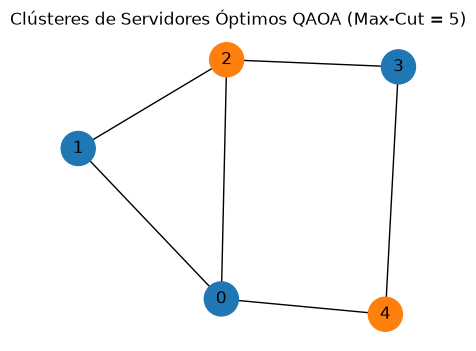

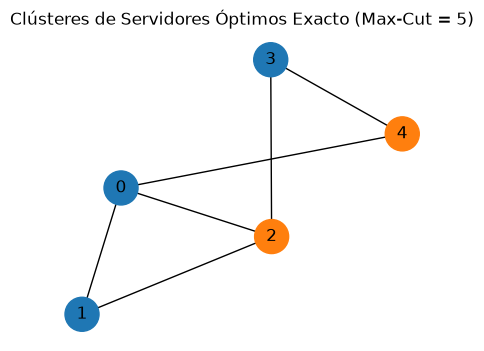

In [18]:
n_servidores = 5
aristas_red = [(0, 1), (0, 2), (0, 4), (1, 2), (2, 3), (3, 4)]

grafo_red = rx.PyGraph()
grafo_red.add_nodes_from(range(n_servidores))
grafo_red.add_edges_from([(u, v, 1.0) for u, v in aristas_red])

# Construir matriz QUBO
Q_redes = np.zeros((n_servidores, n_servidores))
for u, v in aristas_red:
    Q_redes[u, u] -= 1.0
    Q_redes[v, v] -= 1.0
    Q_redes[min(u, v), max(u, v)] += 2.0

H_redes = qubo_to_ising_hamiltonian(Q_redes)
print("Hamiltoniano Max-Cut (solo términos ZZ):\n", H_redes)

mejor_x_redes, dist_redes, hist_redes, _ = resolver_con_qaoa_local(H_redes, reps=2)
opt_x_redes, _ = fuerza_bruta_qubo(Q_redes)

corte_qaoa = sum(1 for u, v in aristas_red if mejor_x_redes[u] != mejor_x_redes[v])
corte_exacto = sum(1 for u, v in aristas_red if opt_x_redes[u] != opt_x_redes[v])

print(f"\nPartición QAOA (q0..q4):     {mejor_x_redes} -> Enlaces cortados: {corte_qaoa}/{len(aristas_red)}")
print(f"Partición Clásica Exacta:   {opt_x_redes} -> Enlaces cortados: {corte_exacto}/{len(aristas_red)}")

# Visualizar el grafo particionado
colores = ["tab:blue" if b == 0 else "tab:orange" for b in mejor_x_redes]
plt.figure(figsize=(5, 4))
plt.title(f"Clústeres de Servidores Óptimos QAOA (Max-Cut = {corte_qaoa})")
draw_graph(grafo_red, node_color=colores, node_size=600, with_labels=True)
plt.show()
plt.figure(figsize=(5, 4))
plt.title(f"Clústeres de Servidores Óptimos Exacto (Max-Cut = {corte_exacto})")
draw_graph(grafo_red, node_color=colores, node_size=600, with_labels=True)
plt.show()

---
## Caso 2 — Data Science: Selección de Características (*Feature Selection*) con `scikit-learn`

### Explicación de la Función Objetivo (*Target Function*)
En problemas reales de Machine Learning, muchas variables predictoras son altamente colineales (por ejemplo, el **radio**, el **perímetro** y el **área** de un tumor en el dataset *Breast Cancer Wisconsin*). Incluir variables redundantes degrada la interpretabilidad y causa sobreajuste.

Cargaremos las primeras **6 variables reales** del dataset *Breast Cancer* de `scikit-learn` y buscaremos el subconjunto óptimo de variables ($x_i = 1$ si seleccionamos la variable $i$, $x_i = 0$ si la descartamos) que:
1. **Maximice la Relevancia** respecto a la variable objetivo $Y$: $R_i = |\text{Corr}(X_i, Y)|$.
2. **Minimice la Redundancia** (colinealidad) entre pares de variables seleccionadas: $S_{ij} = |\text{Corr}(X_i, X_j)|$.

$$\min_{x \in \{0,1\}^6} \left( -\sum_{i=0}^{5} R_i x_i + \alpha \sum_{0 \le i < j < 6} S_{ij} x_i x_j \right)$$

In [16]:
# Cargar dataset real Breast Cancer de scikit-learn
cancer = load_breast_cancer()
n_features = 6
nombres_features = [str(f) for f in cancer.feature_names[:n_features]]

df_X = pd.DataFrame(cancer.data[:, :n_features], columns=nombres_features)
serie_y = pd.Series(cancer.target, name="Diagnostico")

# 1. Vector de Relevancia R_i = |Corr(X_i, Y)|
relevancia = df_X.apply(lambda col: abs(col.corr(serie_y))).values

# 2. Matriz de Redundancia S_ij = |Corr(X_i, X_j)| (Triangular superior)
corr_matrix = df_X.corr().abs().values
redundancia = np.triu(corr_matrix, 1)

print("Relevancia con el Target Y:")
for name, rel in zip(nombres_features, relevancia):
    print(f"  - {name:<18}: {rel:.3f}")

print("\nNota de colinealidad: Corr(mean radius, mean perimeter) =", f"{redundancia[0, 2]:.3f}")
print("Nota de colinealidad: Corr(mean radius, mean area)      =", f"{redundancia[0, 3]:.3f}")

# Construir matriz QUBO: min (-R_i * x_i + alpha * S_ij * x_i * x_j)
alpha_colinealidad = 0.85
Q_ml = np.diag(-relevancia) + alpha_colinealidad * redundancia

H_ml = qubo_to_ising_hamiltonian(Q_ml)
mejor_x_ml, dist_ml, hist_ml, _ = resolver_con_qaoa_local(H_ml, reps=3)
opt_x_ml, _ = fuerza_bruta_qubo(Q_ml)

seleccion_qaoa = [nombres_features[i] for i in range(n_features) if mejor_x_ml[i] == 1]
seleccion_exacta = [nombres_features[i] for i in range(n_features) if opt_x_ml[i] == 1]

print(f"\nVector QAOA:            {mejor_x_ml}")
print(f"Features QAOA:          {seleccion_qaoa}")
print(f"Features Óptimo Exacto: {seleccion_exacta}")

Relevancia con el Target Y:
  - mean radius       : 0.730
  - mean texture      : 0.415
  - mean perimeter    : 0.743
  - mean area         : 0.709
  - mean smoothness   : 0.359
  - mean compactness  : 0.597

Nota de colinealidad: Corr(mean radius, mean perimeter) = 0.998
Nota de colinealidad: Corr(mean radius, mean area)      = 0.987

Vector QAOA:            [1 1 0 0 1 0]
Features QAOA:          ['mean radius', 'mean texture', 'mean smoothness']
Features Óptimo Exacto: ['mean radius', 'mean texture', 'mean smoothness']


**Interpretación del resultado de Data Science:** Observa cómo de las tres variables geométricas altamente redundantes (`mean radius`, `mean perimeter`, `mean area`, que tienen correlación $\approx 0.99$ entre sí), el algoritmo **selecciona únicamente `mean radius`** (la de mayor correlación con el diagnóstico: $0.730$) y descarta automáticamente `mean perimeter` y `mean area`, combinándola con variables independientes como `mean texture` y `mean compactness`.

---
## Caso 3 — Finanzas Cuantitativas: Optimización de Portafolio

### Explicación de la Función Objetivo (*Target Function*)
Un inversionista evalúa **5 activos financieros** y su presupuesto le permite comprar **exactamente $K = 2$ activos**. Desea maximizar el retorno esperado $\mu_i$, minimizar el riesgo del portafolio (covarianza $\sigma_{ij}$ ponderada por la aversión al riesgo $q$) y cumplir la restricción de presupuesto $\sum_i x_i = K$ mediante una penalización cuadrática $\lambda$:

$$\min_{x \in \{0,1\}^5} \left( q \sum_{i,j} \sigma_{ij} x_i x_j - \sum_{i} \mu_i x_i + \lambda \left( \sum_{i} x_i - K \right)^2 \right)$$

In [13]:
activos = ["Tech_A", "Tech_B", "Energía_C", "Oro_D", "Bonos_E"]
n_activos = len(activos)
K_presupuesto = 2

# Retornos anuales esperados
mu = np.array([0.18, 0.16, 0.12, 0.08, 0.05])

# Matriz de Covarianza (Tech_A y Tech_B tienen alta covarianza positiva;
# Oro_D tiene covarianza negativa con Tech, ideal para cobertura/hedging)
sigma = np.array([
    [ 0.10,  0.09,  0.02, -0.03,  0.00],
    [ 0.09,  0.09,  0.02, -0.02,  0.00],
    [ 0.02,  0.02,  0.06,  0.01,  0.01],
    [-0.03, -0.02,  0.01,  0.04,  0.00],
    [ 0.00,  0.00,  0.01,  0.00,  0.01],
])

q_riesgo = 1.5
lambda_pen = 1.0

# Construir matriz QUBO
Q_fin = np.zeros((n_activos, n_activos))
for i in range(n_activos):
    Q_fin[i, i] = q_riesgo * sigma[i, i] - mu[i] + lambda_pen * (1 - 2 * K_presupuesto)
    for j in range(i + 1, n_activos):
        Q_fin[i, j] = 2 * q_riesgo * sigma[i, j] + 2 * lambda_pen

H_fin = qubo_to_ising_hamiltonian(Q_fin)
mejor_x_fin, dist_fin, hist_fin, _ = resolver_con_qaoa_local(H_fin, reps=3)
opt_x_fin, _ = fuerza_bruta_qubo(Q_fin)

portafolio_qaoa = [activos[i] for i in range(n_activos) if mejor_x_fin[i] == 1]
portafolio_exacto = [activos[i] for i in range(n_activos) if opt_x_fin[i] == 1]

print(f"Vector Portafolio QAOA:   {mejor_x_fin} -> Activos: {portafolio_qaoa}")
print(f"Vector Portafolio Exacto: {opt_x_fin} -> Activos: {portafolio_exacto}")

Vector Portafolio QAOA:   [1 0 0 1 0] -> Activos: ['Tech_A', 'Oro_D']
Vector Portafolio Exacto: [1 0 0 1 0] -> Activos: ['Tech_A', 'Oro_D']


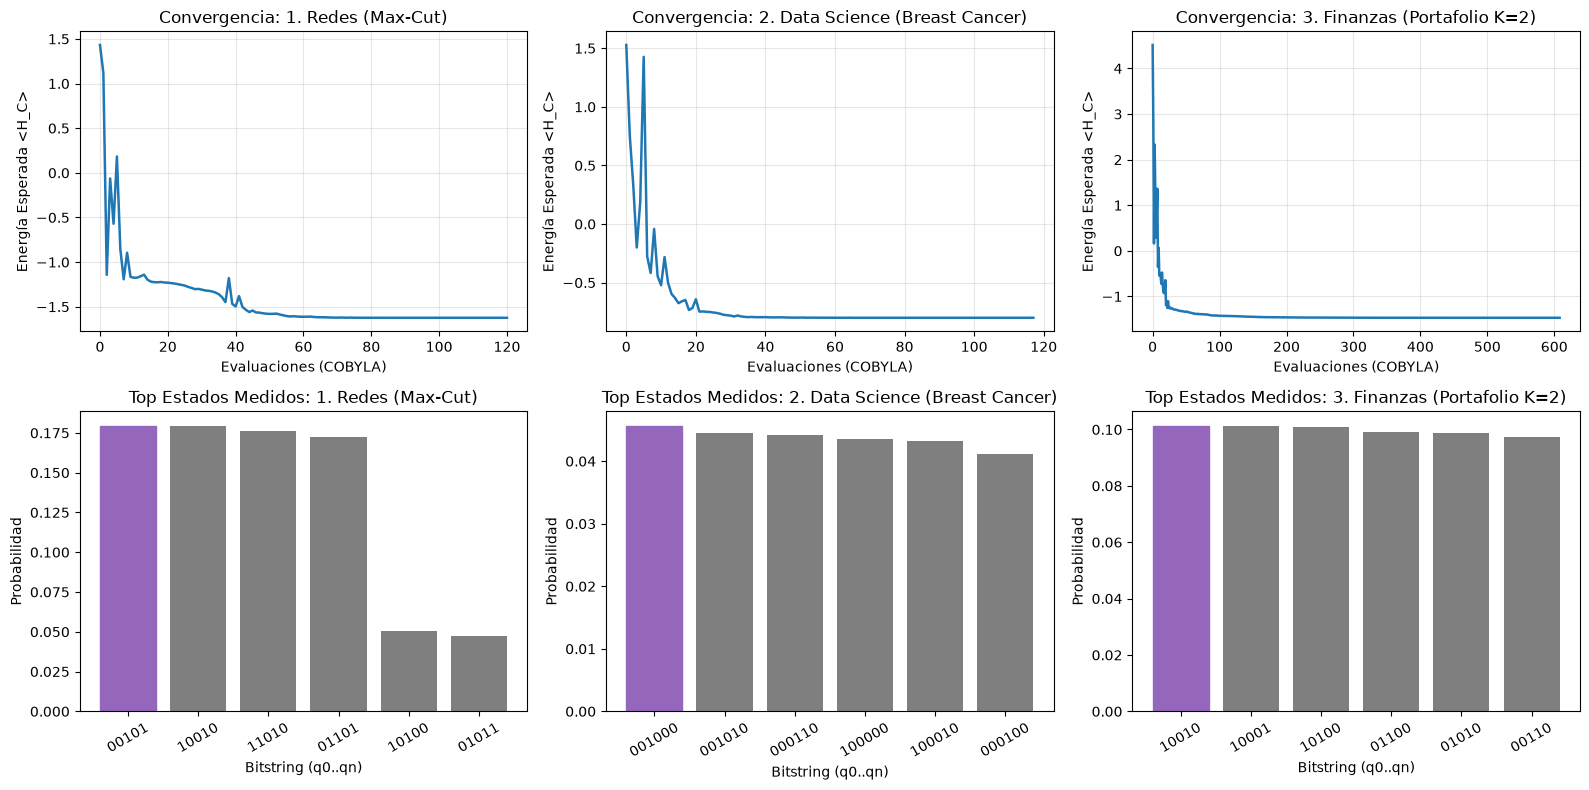

In [14]:
# Visualización comparativa de los 3 casos con QAOA
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

casos = [
    ("1. Redes (Max-Cut)", hist_redes, dist_redes),
    ("2. Data Science (Breast Cancer)", hist_ml, dist_ml),
    ("3. Finanzas (Portafolio K=2)", hist_fin, dist_fin),
]

for col, (titulo, hist, dist) in enumerate(casos):
    # Curva de convergencia
    axes[0, col].plot(hist, color="tab:blue", lw=1.8)
    axes[0, col].set_title(f"Convergencia: {titulo}")
    axes[0, col].set_xlabel("Evaluaciones (COBYLA)")
    axes[0, col].set_ylabel("Energía Esperada <H_C>")
    axes[0, col].grid(True, alpha=0.3)
    
    # Top 6 bitstrings medidos
    top_items = sorted(dist.items(), key=lambda x: x[1], reverse=True)[:6]
    etiquetas = [k for k, _ in top_items]
    probs = [v for _, v in top_items]
    
    barras = axes[1, col].bar(etiquetas, probs, color="tab:grey")
    barras[0].set_color("tab:purple")
    axes[1, col].set_title(f"Top Estados Medidos: {titulo}")
    axes[1, col].set_xlabel("Bitstring (q0..qn)")
    axes[1, col].set_ylabel("Probabilidad")
    axes[1, col].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

---
## Bonus de Escala Media: Pauli Correlation Encoding (PCE) en Simulador Local

¿Qué pasa si queremos optimizar un problema de **36 nodos**, pero estamos en un simulador local y no podemos simular 36 qubits (lo cual requeriría $2^{36} \approx 68$ mil millones de amplitudes complejas)?

Aplicando la técnica de **Pauli Correlation Encoding (PCE)** con correlaciones de $k=2$ cuerpos en $X$, $Y$ y $Z$, podemos codificar $m = \frac{3}{2} n (n-1)$ variables clásicas usando solo $n$ qubits:
* Con **$n = 6$ qubits**, podemos comprimir exactamente **$m = \frac{3}{2}(6)(5) = 45$ nodos** (o cualquier grafo de hasta 45 nodos, como $m=36$).
* Cada nodo $i$ se asigna a una cadena de Pauli $\Pi_i$ de peso 2 (por ejemplo, $I \otimes I \otimes X \otimes X \otimes I \otimes I$), y su partición se decide por el signo del valor esperado: $x_i = \text{sgn}(\langle \Pi_i \rangle)$.
* La función de pérdida suave relajada a minimizar es:
$$\mathcal{L}(\theta) = \sum_{(i,j) \in E} \tanh(\alpha \langle \Pi_i \rangle) \tanh(\alpha \langle \Pi_j \rangle) + \mathcal{L}^{(\text{reg})}$$

Nodos del problema: 36 | Qubits requeridos con PCE: 6
Valor del corte alcanzado con PCE (6 qubits): 86 de 135 aristas totales


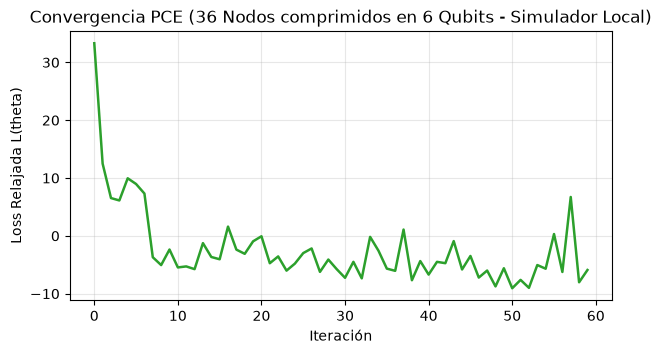

In [15]:
# Grafo aleatorio de 36 nodos resuelto con SOLO 6 QUBITS usando PCE en simulador local
num_nodes_pce = 36
grafo_pce = rx.undirected_gnp_random_graph(num_nodes_pce, 0.2, seed=42)

# Calcular número de qubits necesarios según m = (3/2) * n * (n - 1)
num_qubits_pce = int(np.ceil((1 + np.sqrt(1 + (8 / 3) * num_nodes_pce)) / 2))
print(f"Nodos del problema: {num_nodes_pce} | Qubits requeridos con PCE: {num_qubits_pce}")

list_size = num_nodes_pce // 3
node_x = list(range(0, list_size))
node_y = list(range(list_size, 2 * list_size))
node_z = list(range(2 * list_size, num_nodes_pce))

def build_pce_ops(pauli_char, node_list, n, k=2):
    ops = []
    for idx, c in enumerate(combinations(range(n), k)):
        if idx >= len(node_list):
            break
        paulis = ["I"] * n
        paulis[c[0]], paulis[c[1]] = pauli_char, pauli_char
        ops.append(SparsePauliOp.from_list([("".join(paulis)[::-1], 1.0)]))
    return ops

pce_x = build_pce_ops("X", node_x, num_qubits_pce)
pce_y = build_pce_ops("Y", node_y, num_qubits_pce)
pce_z = build_pce_ops("Z", node_z, num_qubits_pce)
todos_los_ops_pce = pce_x + pce_y + pce_z

# Circuito variacional compacto efficient_su2 en 6 qubits
qc_pce = efficient_su2(num_qubits_pce, su2_gates=["ry", "rz"], reps=2).decompose()
estimator_pce = StatevectorEstimator()
historial_pce = []
mejor_mapa_exp = {}
min_loss_pce = float("inf")

def loss_func_pce(params):
    global min_loss_pce, mejor_mapa_exp
    # Evaluamos todos los operadores de Pauli en una sola llamada vectorizada al simulador
    job = estimator_pce.run([(qc_pce, todos_los_ops_pce, params)])
    evs = job.result()[0].data.evs
    
    alpha = num_qubits_pce
    tanh_vals = np.tanh(alpha * evs)
    
    # Suma sobre las aristas
    loss = sum(tanh_vals[u] * tanh_vals[v] for u, v in grafo_pce.edge_list())
    
    # Término de regularización
    reg = (np.mean(tanh_vals**2)) ** 2
    v_factor = len(grafo_pce.edges()) / 2 + (num_nodes_pce - 1) / 4
    loss += 0.5 * v_factor * reg
    
    historial_pce.append(float(loss))
    if loss < min_loss_pce:
        min_loss_pce = float(loss)
        mejor_mapa_exp = {i: evs[i] for i in range(num_nodes_pce)}
    return float(loss)

init_pce = np.random.rand(qc_pce.num_parameters)
res_pce = minimize(loss_func_pce, init_pce, method="COBYLA", options={"maxiter": 60, "rhobeg": 1.0})

# Decodificar partición según el signo del valor esperado <Pi_i>
particion_pce = [1 if mejor_mapa_exp[i] >= 0 else 0 for i in range(num_nodes_pce)]
corte_pce = sum(1 for u, v in grafo_pce.edge_list() if particion_pce[u] != particion_pce[v])

print(f"Valor del corte alcanzado con PCE (6 qubits): {corte_pce} de {len(grafo_pce.edges())} aristas totales")

plt.figure(figsize=(7, 3.5))
plt.plot(historial_pce, color="tab:green", lw=1.8)
plt.title("Convergencia PCE (36 Nodos comprimidos en 6 Qubits - Simulador Local)")
plt.xlabel("Iteración")
plt.ylabel("Loss Relajada L(theta)")
plt.grid(True, alpha=0.3)
plt.show()